# Shuttle: cost, value and policy

Loads the reported solver results without training. Cost is minimized; reward value is its negative. See `../mlds_assignment1_submission/ASSIGNMENT1_REPORT.pdf` for the model, assumptions and validation.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
ROOT=Path.cwd()
if not (ROOT/'shuttle.py').exists(): ROOT=ROOT/'mlds_assignment1_shuttle'
data=np.load(ROOT/'results/shuttle_results.npz')
FIG=ROOT/'results/figures';FIG.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.2})
def curve(values,label,title,name):
    fig,ax=plt.subplots(figsize=(8,3.5))
    ax.plot(data['states'],values)
    ax.set(xlabel='Passengers waiting before dispatch',ylabel=label,title=title,xlim=(0,200))
    fig.tight_layout()
    for ext in ('png','pdf'):fig.savefig(FIG/f'{name}.{ext}',dpi=170)
    plt.show()


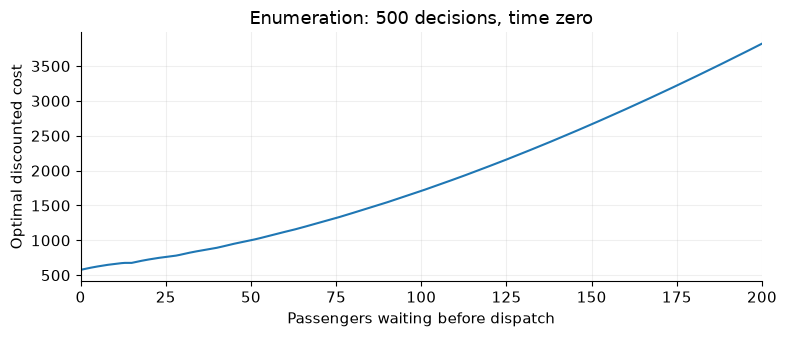

In [2]:
curve(data['finite_costs'][0],'Optimal discounted cost','Enumeration: 500 decisions, time zero','finite_cost')

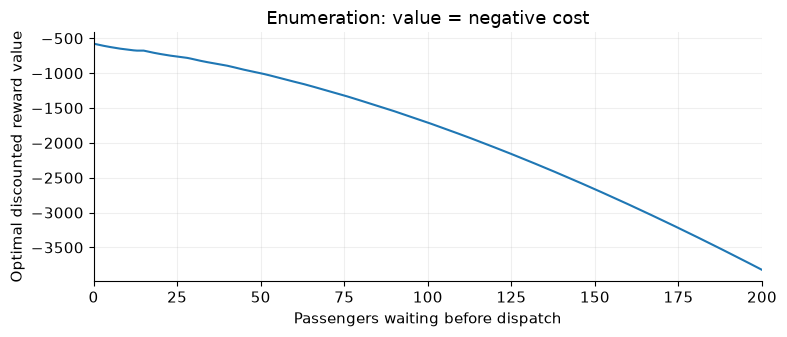

In [3]:
curve(-data['finite_costs'][0],'Optimal discounted reward value','Enumeration: value = negative cost','finite_value')

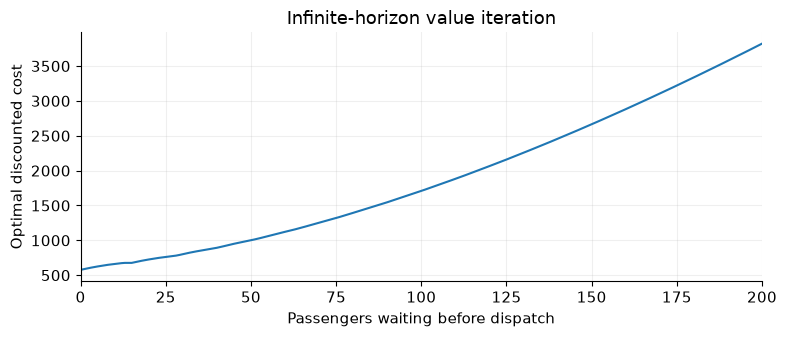

In [4]:
curve(data['vi_cost'],'Optimal discounted cost','Infinite-horizon value iteration','infinite_cost')

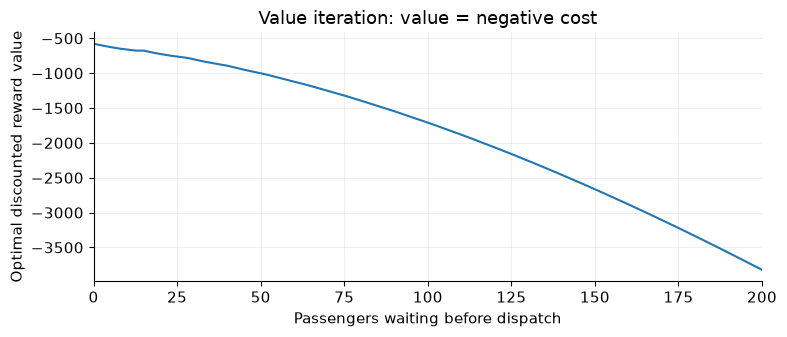

In [5]:
curve(-data['vi_cost'],'Optimal discounted reward value','Value iteration: value = negative cost','infinite_value')

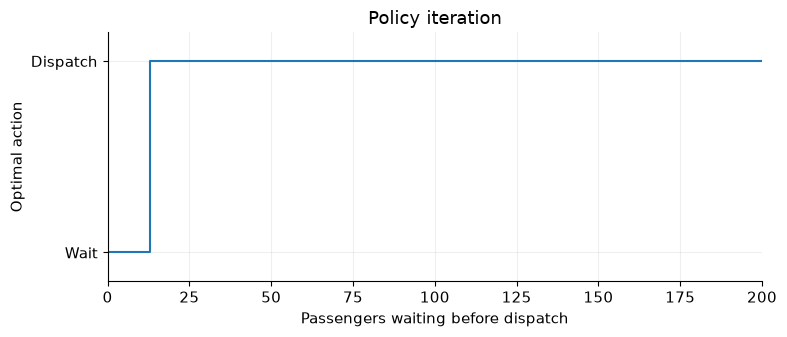

In [6]:
fig,ax=plt.subplots(figsize=(8,3.5))
ax.step(data['states'],data['pi_policy'],where='post')
ax.set(xlabel='Passengers waiting before dispatch',ylabel='Optimal action',title='Policy iteration',xlim=(0,200),ylim=(-.15,1.15))
ax.set_yticks([0,1],['Wait','Dispatch'])
fig.tight_layout()
for ext in ('png','pdf'):fig.savefig(FIG/f'policy.{ext}',dpi=170)
plt.show()
